# 01. Data cleaning and exploratory analysis

Telecom Customer Churn (Iranian churn dataset, UCI). This notebook covers guideline steps 1-5: overall churn rate, churn by key variables, distributions and outliers, leakage review, and data preparation.

In [1]:
import sys
sys.path.insert(0, '../python')          # reusable code lives in /python
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from data_preprocessing import load_raw, clean, save_clean, FEATURES
import exploratory_analysis as eda

## 1. Load and inspect the raw data

In [2]:
raw = load_raw()
print('Rows:', len(raw), '| columns:', raw.shape[1])
print('Missing values:', int(raw.isna().sum().sum()))
print('Duplicated rows:', int(raw.duplicated().sum()))
raw.head()

Rows: 3150 | columns: 14
Missing values: 0
Duplicated rows: 300


,Call_Failure,Complains,Subscription_Length,Charge_Amount,Seconds_of_Use,Frequency_of_use,Frequency_of_SMS,Distinct_Called_Numbers,Age_Group,Tariff_Plan,Status,Age,Customer_Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


## 2. Cleaning

300 identical rows are removed so the same customer cannot appear in both the training and the test set. A customer ID and readable labels are added.

In [3]:
df = clean(raw)
print('Unique customers:', len(df))
print(f'Overall churn rate: {df.Churn.mean()*100:.1f}% ({df.Churn.sum()} churned customers)')
df[['CustomerID','Status_Label','Tariff_Plan_Label','Complains_Label','Subscription_Band','Churn_Label']].head()

Unique customers: 2850
Overall churn rate: 15.6% (446 churned customers)


,CustomerID,Status_Label,Tariff_Plan_Label,Complains_Label,Subscription_Band,Churn_Label
0,C0001,Active,Pay as you go,No,37m+,Stayed
1,C0002,Non-active,Pay as you go,No,37m+,Stayed
2,C0003,Active,Pay as you go,No,37m+,Stayed
3,C0004,Active,Pay as you go,No,37m+,Stayed
4,C0005,Active,Pay as you go,No,37m+,Stayed


## 3. Churn by customer attributes

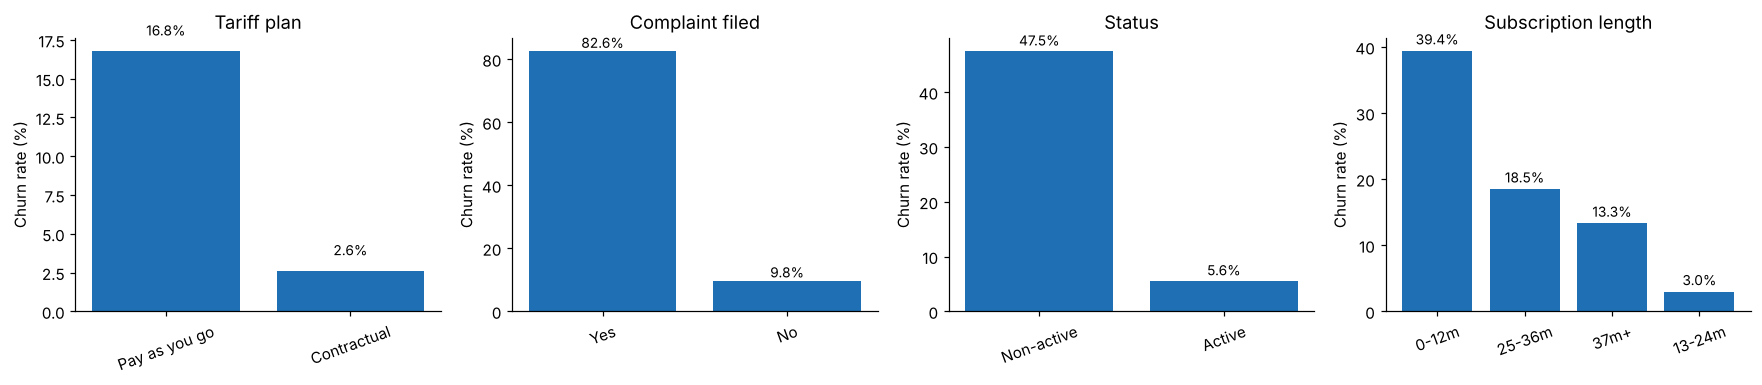

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col, title in zip(axes, ['Tariff_Plan_Label', 'Complains_Label', 'Status_Label', 'Subscription_Band'],
                          ['Tariff plan', 'Complaint filed', 'Status', 'Subscription length']):
    s = (df.groupby(col).Churn.mean() * 100).sort_values(ascending=False)
    ax.bar(s.index, s.values, color='#1F6FB5'); ax.set_title(title); ax.set_ylabel('Churn rate (%)')
    for i, v in enumerate(s.values): ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## 4. Churn by quartile of each numeric variable

Q1 is the lowest 25% of customers and Q4 the highest 25%.

In [5]:
q = eda.quartile_table(df)
q.pivot(index='Variable', columns='Quartile', values='churn_pct')[['Q1 low','Q2','Q3','Q4 high']]

Quartile,Q1 low,Q2,Q3,Q4 high
Variable,,,,
Call_Failure,17.1,16.0,13.9,15.6
Customer_Value,34.4,18.3,9.3,0.7
Distinct_Called_Numbers,30.7,17.6,11.8,2.5
Frequency_of_SMS,21.0,23.6,17.3,0.7
Frequency_of_use,31.1,23.0,6.9,1.5
Seconds_of_Use,34.6,19.0,9.0,0.0
Subscription_Length,12.2,21.6,16.7,12.1


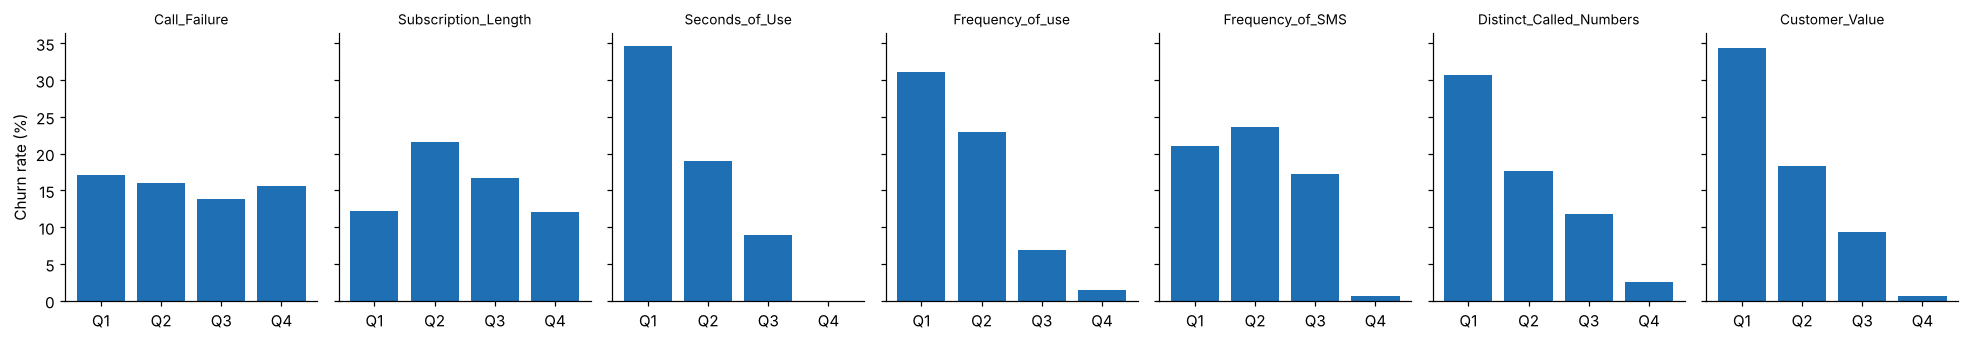

In [6]:
fig, axes = plt.subplots(1, len(eda.NUM), figsize=(18, 3.2), sharey=True)
for ax, c in zip(axes, eda.NUM):
    t = q[q.Variable == c]
    ax.bar(range(4), t.churn_pct, color='#1F6FB5'); ax.set_xticks(range(4)); ax.set_xticklabels(['Q1','Q2','Q3','Q4']); ax.set_title(c, fontsize=9)
axes[0].set_ylabel('Churn rate (%)'); plt.tight_layout(); plt.show()

Usage variables fall steeply from Q1 to Q4 (for example seconds of use: 34.6% to 0.0%), customer value follows the same pattern, and call failures show no clear trend. Subscription length is not linear: churn peaks in Q2.

## 5. Distributions and outliers

Outliers are detected with the IQR rule (more than 1.5 x IQR above Q3).

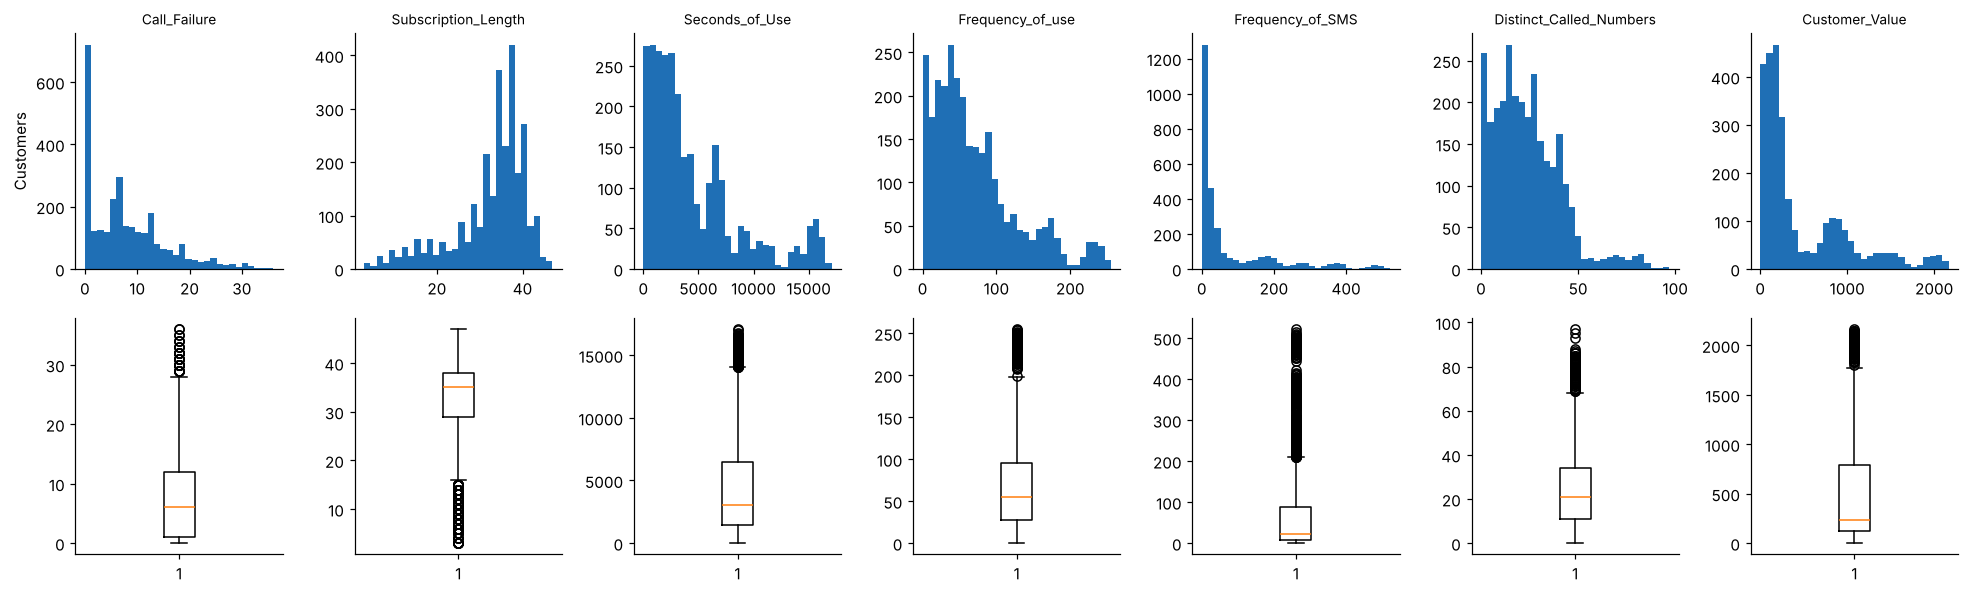

In [7]:
fig, axes = plt.subplots(2, len(eda.NUM), figsize=(18, 5.5))
for k, c in enumerate(eda.NUM):
    axes[0, k].hist(df[c], bins=30, color='#1F6FB5'); axes[0, k].set_title(c, fontsize=9)
    axes[1, k].boxplot(df[c])
axes[0, 0].set_ylabel('Customers'); plt.tight_layout(); plt.show()

In [8]:
eda.outlier_table(df)

,Variable,Mean,Median,Max,Skew,Outliers_IQR,Outlier_Churn_Rate_pct
0,Call_Failure,7.80,6.00,36.00,1.07,44,20.45
1,Subscription_Length,32.45,35.00,47.00,-1.25,0,NaN
2,Seconds_of_Use,4534.24,3041.00,17090.00,1.31,189,0.00
3,Frequency_of_use,70.48,54.50,255.00,1.15,118,0.00
4,Frequency_of_SMS,73.79,22.00,522.00,1.97,333,0.00
5,Distinct_Called_Numbers,23.87,21.00,97.00,1.04,82,0.00
6,Customer_Value,474.99,232.52,2165.28,1.42,104,0.00


**Decision: outliers are kept.** The heavy users are real customers, and their churn rate is 0.0% (call failures are the exception, at about 20%). Removing them would delete the most loyal customers and bias the churn rate upward. Tree models handle skewed data without transformation.

## 6. Leakage review

Each feature is checked for where it comes from and whether it is known when the prediction is made (after 9 months of activity, before the 3-month gap).

In [9]:
eda.LEAKAGE_REVIEW

,Feature,Source,Available_At_Prediction,Leakage_Risk
0,Call_Failure,9-month summary,Yes,Low
1,Complains,Flag from the 9-month window,Yes,Medium: complaint may be filed at the point of...
2,Subscription_Length,Account age at observation,Yes,Low
3,Charge_Amount,9-month billing band,Yes,Low
4,Seconds_of_Use,9-month total,Yes,Low
5,Frequency_of_use,9-month total,Yes,Low
6,Frequency_of_SMS,9-month total,Yes,Low
7,Distinct_Called_Numbers,9-month total,Yes,Low
8,Tariff_Plan,Contract type at observation,Yes,Low
9,Status,Active/non-active at observation,Yes,Medium: non-active may already mean disengaged...


No feature is a direct leak. `Complains` and `Status` are rated Medium: the business should confirm both are recorded before the 3-month gap.

## 7. Data preparation decisions

- **Target separated:** `Churn` (1 = left, 0 = stayed) is kept apart from the 12 inputs.
- **Encoding:** `Tariff_Plan`, `Status` and `Complains` are already binary codes and `Charge_Amount` is an ordinal band, so they stay numeric. `Age_Group` repeats `Age` and is dropped.
- **Scaling:** only Logistic Regression is scaled (`StandardScaler` inside its pipeline); tree models do not need it.
- **Duplicates:** 300 duplicated records removed (above).
- **Split:** a stratified 75/25 train/test split is created in notebook 02 so both sets keep the 15.6% churn rate.

In [10]:
clean_df = save_clean(df)
print('Saved data/processed/churn_clean.csv', clean_df.shape)
print('Model inputs:', FEATURES)

Saved data/processed/churn_clean.csv (2850, 18)
Model inputs: ['Call_Failure', 'Complains', 'Subscription_Length', 'Charge_Amount', 'Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Tariff_Plan', 'Status', 'Age', 'Customer_Value']
